# 02 Transfermarkt match

**Owner:** Devarshi

**Goal:** a crosswalk FIFA `player_id` ↔ Transfermarkt `player_id` for every cohort entrant, then
real-world outcomes for every matched player.

**Match rule (CLAUDE.md §8):** date of birth must match exactly (any of the player's FIFA DOB variants, see
notebook 01). Among same-DOB candidates take the best rapidfuzz `token_set_ratio` on normalised names
(`src/names.py`). Accept if ≥ 85. Scores of 70–84, ties, and every potential-85+ player go to
`reports/match_review.csv`. Confirmed or corrected pairs are read back from `data/manual/tm_match_overrides.csv`.

**How to review:** open `reports/match_review.csv`. For each player, add one row to
`data/manual/tm_match_overrides.csv` with columns `fifa_player_id, tm_player_id, action, reviewer, note`, where
`action` is `confirm` (accept this TM id), `correct` (use a different TM id) or `reject` (no match).
Re-run this notebook. Reviewed players drop out of the review file.

**Outputs:** `data/clean/tm_crosswalk.parquet` (one row per cohort entrant), `data/clean/real_outcomes.parquet`
(one row per matched entrant), section `02` of `reports/data_quality.md`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, dq, matching as m
from src.names import normalise

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

CHECKS, NOTES = [], []
def check(name, passed, detail=""):
    CHECKS.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": detail})
    print(("PASS" if passed else "FAIL"), "-", name, ("| " + detail if detail else ""))
    return passed

## 1. Inputs

In [2]:
coh = pd.read_parquet(config.CLEAN / "cohort.parquet")
tm_players_raw = pd.read_csv(config.RAW_TM / "players.csv")
print("cohort:", coh.shape, "| TM players:", tm_players_raw.shape)
display(tm_players_raw[["player_id", "name", "first_name", "last_name", "date_of_birth", "position",
                        "current_club_name", "last_season"]].head())

check("TM player_id is unique", tm_players_raw["player_id"].is_unique)
n_no_dob = int(pd.to_datetime(tm_players_raw["date_of_birth"], errors="coerce").isna().sum())
print(f"TM players without a usable DOB (cannot be matched): {n_no_dob}")
NOTES.append(f"{n_no_dob} Transfermarkt players have no usable date of birth and cannot be matched.")

cohort: (11519, 103) | TM players: (50149, 26)


,player_id,name,first_name,last_name,date_of_birth,position,current_club_name,last_season
0,10,Miroslav Klose,Miroslav,Klose,1978-06-09 00:00:00,Attack,Società Sportiva Lazio S.p.A.,2015
1,26,Roman Weidenfeller,Roman,Weidenfeller,1980-08-06 00:00:00,Goalkeeper,Borussia Dortmund,2017
2,65,Dimitar Berbatov,Dimitar,Berbatov,1981-01-30 00:00:00,Attack,Panthessalonikios Athlitikos Omilos Konstantin...,2015
3,77,Lúcio,NaN,Lúcio,1978-05-08 00:00:00,Defender,Juventus FC,2012
4,80,Tom Starke,Tom,Starke,1981-03-18 00:00:00,Goalkeeper,Bayern Munich,2017


PASS - TM player_id is unique 
TM players without a usable DOB (cannot be matched): 49


## 2. Name normalisation
Transfermarkt has no short-name column, so a FIFA-style short name (first initial + last name) is built from
`first_name` / `last_name`. Names compared: FIFA `long_name`, `short_name` × TM `name`, `first_name last_name`,
initial + `last_name`. The score is the best pair.

In [3]:
examples = ["Kylian Mbappé Lottin", "K. Mbappé", "N'Golo Kanté", "Vinícius Jr.", "Raphael Guimarães de Paula",
            "Jean-Clair Todibo", "Martin Ødegaard", "Júnior"]
display(pd.DataFrame({"raw": examples, "normalised": [normalise(x) for x in examples]}))

fifa = m.prepare_fifa(coh)
tm = m.prepare_tm(tm_players_raw)
display(tm[["player_id", "name", "dob", "tm_names"]].head())

,raw,normalised
0,Kylian Mbappé Lottin,kylian mbappe lottin
1,K. Mbappé,k mbappe
2,N'Golo Kanté,ngolo kante
3,Vinícius Jr.,vinicius
4,Raphael Guimarães de Paula,raphael guimaraes de paula
5,Jean-Clair Todibo,jean clair todibo
6,Martin Ødegaard,martin odegaard
7,Júnior,junior


,player_id,name,dob,tm_names
0,10,Miroslav Klose,1978-06-09,"[m klose, miroslav klose]"
1,26,Roman Weidenfeller,1980-08-06,"[r weidenfeller, roman weidenfeller]"
2,65,Dimitar Berbatov,1981-01-30,"[d berbatov, dimitar berbatov]"
3,77,Lúcio,1978-05-08,[lucio]
4,80,Tom Starke,1981-03-18,"[t starke, tom starke]"


## 3. Candidates and best match

In [4]:
cands = m.score_candidates(fifa, tm)
best = m.best_matches(fifa, cands)
print(f"Same-DOB candidate pairs: {len(cands):,}")

info = coh[["player_id", "short_name", "long_name", "dob", "dob_variants", "entry_edition_label", "potential",
            "potential_band", "position_group", "club_name", "nationality_name"]].rename(columns={"player_id": "fifa_player_id"})
best = best.merge(info, on="fifa_player_id", how="left")
display(best["match_class"].value_counts().rename("players").to_frame())
display(pd.crosstab(best["potential_band"], best["match_class"]))

Same-DOB candidate pairs: 90,037


,players
match_class,
auto,6599
no_match_below_70,4848
review_low_score,40
no_dob_candidate,21
review_tie,11


match_class,auto,no_dob_candidate,no_match_below_70,review_low_score,review_tie
potential_band,,,,,
<70,2387,14,3410,25,4
70–74,2105,5,1067,11,3
75–79,1462,1,315,2,4
80–84,543,1,56,0,0
85+,102,0,0,2,0


### Extra review triggers
Beyond the §8 triggers (70–84, ties, potential 85+), two cheap plausibility checks also send an auto match
to review, without un-accepting it: the goalkeeper flag disagrees between FIFA and Transfermarkt, or one
Transfermarkt player is the best match for more than one FIFA player (then neither is accepted until reviewed).

In [5]:
tm_info = tm.set_index("player_id")[["name", "dob", "position", "current_club_name", "country_of_citizenship", "url"]]
best = best.join(tm_info.add_prefix("tm_"), on="tm_player_id")

is_auto = best["match_class"] == "auto"
gk_mismatch = is_auto & ((best["position_group"] == "GK") != (best["tm_position"] == "Goalkeeper")) \
              & best["tm_position"].ne("Missing")
# Only auto matches can claim a TM id; a rejected low-score candidate must not block a real match.
auto_ids = best.loc[is_auto, "tm_player_id"]
dup_tm = is_auto & best["tm_player_id"].isin(auto_ids[auto_ids.duplicated(keep=False)])
wonderkid = best["potential"] >= config.WONDERKID_POTENTIAL

best["review_reasons"] = ""
def add_reason(mask, reason):
    best.loc[mask, "review_reasons"] = (best.loc[mask, "review_reasons"] + ";" + reason).str.strip(";")
add_reason(best["match_class"] == "review_low_score", "score 70-84")
add_reason(best["match_class"] == "review_tie", "tie")
add_reason(wonderkid, "potential 85+")
add_reason(gk_mismatch, "GK flag differs")
add_reason(dup_tm, "TM id matched twice")

print("Auto matches with GK flag differing:", int(gk_mismatch.sum()))
print("Auto matches sharing a TM id:", int(dup_tm.sum()))
display(best.loc[dup_tm, ["fifa_player_id", "short_name", "dob", "club_name", "tm_player_id", "tm_name", "score"]])

Auto matches with GK flag differing: 5
Auto matches sharing a TM id: 18


,fifa_player_id,short_name,dob,club_name,tm_player_id,tm_name,score
1269,209475,J. O'Sullivan,1993-09-18,Blackburn Rovers,173592,John O'Sullivan,100.000000
1594,210972,Manquillo,1994-05-05,Liverpool,162029,Javier Manquillo,100.000000
1739,211510,Manquillo,1994-05-05,Alcorcón,162029,Javier Manquillo,100.000000
2966,216818,M. O'Sullivan,1993-09-18,West Bromwich Albion,173592,John O'Sullivan,90.909091
3902,221630,A. Sánchez,1997-11-18,Deportivo Pasto,403151,Robert Sánchez,88.888889
4128,222352,A. Ajeti,1997-02-26,Basel,195906,Albian Ajeti,100.000000
4651,223654,San Emeterio,1997-03-16,Racing Santander,307519,Fede San Emeterio,100.000000
5176,224736,K. Eryüksel,1995-08-18,Akhisar Belediyespor,330190,Kenan Eryüksel,100.000000
5177,224738,S. Eryüksel,1995-08-18,Akhisar Belediyespor,330190,Kenan Eryüksel,90.000000
5463,225258,Borja,1997-03-16,Racing Santander,307519,Fede San Emeterio,92.307692


## 4. Apply manual overrides

In [6]:
ov = m.load_overrides()
problems = m.validate_overrides(ov, set(coh["player_id"]), set(tm["player_id"]))
check("Override file is valid", not problems, "; ".join(problems))
assert not problems, problems
print(f"Override rows: {len(ov)}", ov["action"].value_counts().to_dict() if len(ov) else "")

# Accepted before overrides: auto matches, except TM ids claimed twice.
best["accepted_tm_id"] = best["tm_player_id"].where(is_auto & ~dup_tm)
best["match_method"] = np.where(is_auto & ~dup_tm, "auto", "unmatched")
best.loc[best["match_class"].str.startswith("review") | dup_tm, "match_method"] = "pending_review"

ovi = ov.set_index("fifa_player_id")
has_ov = best["fifa_player_id"].isin(ovi.index)
act = best.loc[has_ov, "fifa_player_id"].map(ovi["action"])
ov_tm = best.loc[has_ov, "fifa_player_id"].map(ovi["tm_player_id"])
best.loc[has_ov, "accepted_tm_id"] = ov_tm.where(act != "reject")
best.loc[has_ov, "match_method"] = "override_" + act.map({"confirm": "confirmed", "correct": "corrected", "reject": "rejected"})
best["accepted_tm_id"] = best["accepted_tm_id"].astype("Int64")
best["needs_review"] = (best["review_reasons"] != "") & ~has_ov

dup_after = best["accepted_tm_id"].dropna().duplicated(keep=False)
check("No TM player is accepted for two FIFA players", not dup_after.any(),
      f"{int(dup_after.sum())} rows" if dup_after.any() else "")
display(best["match_method"].value_counts().rename("players").to_frame())

PASS - Override file is valid 
Override rows: 231 {'confirm': 126, 'reject': 88, 'correct': 17}
PASS - No TM player is accepted for two FIFA players 


,players
match_method,
auto,6476
unmatched,4812
override_confirmed,126
override_rejected,88
override_corrected,17


## 5. Review file
One row per candidate. Players with no exact-DOB match and potential ≥ 80 also get up to 3 **near-DOB suggestions**
(born within a year, name score ≥ 85), because a DOB typo in either source is the most common reason a
real player is missed. Suggestions are never accepted automatically.

In [7]:
cols_f = ["fifa_player_id", "short_name", "long_name", "dob", "dob_variants", "entry_edition_label", "potential",
          "position_group", "club_name", "nationality_name"]

# (a) players with a review reason and no override: their top same-DOB candidates
rev_ids = best.loc[best["needs_review"], "fifa_player_id"]
c = cands[cands["fifa_player_id"].isin(rev_ids)].sort_values(["fifa_player_id", "score"], ascending=[True, False])
c["candidate_rank"] = c.groupby("fifa_player_id").cumcount() + 1
c = c[c["candidate_rank"] <= 3].assign(dob_diff_days=0, candidate_type="same DOB")

# (b) unmatched potential-80+ players with no override: near-DOB suggestions
unm = best[best["match_class"].isin(["no_dob_candidate", "no_match_below_70"]) & (best["potential"] >= 80) & ~has_ov]
sugg = m.near_dob_suggestions(fifa[fifa["player_id"].isin(unm["fifa_player_id"])], tm)
sugg["candidate_rank"] = sugg.groupby("fifa_player_id").cumcount() + 1
sugg["candidate_type"] = "near-DOB suggestion"
no_sugg = unm.loc[~unm["fifa_player_id"].isin(sugg["fifa_player_id"]), ["fifa_player_id"]].assign(
    candidate_type="no candidate found", candidate_rank=1)

review = pd.concat([c, sugg, no_sugg], ignore_index=True)
review["tm_player_id"] = review["tm_player_id"].astype("Int64")
review = (review.merge(best[cols_f + ["review_reasons", "match_class", "match_method", "accepted_tm_id"]], on="fifa_player_id")
                .join(tm_info.add_prefix("tm_"), on="tm_player_id"))
review.loc[review["candidate_type"] != "same DOB", "review_reasons"] = "no exact-DOB match (potential 80+)"
review["currently_accepted"] = (review["tm_player_id"] == review["accepted_tm_id"]).fillna(False).map({True: "yes", False: ""})
review["dob"] = review["dob"].dt.strftime("%Y-%m-%d")
review = review.sort_values(["potential", "fifa_player_id", "candidate_rank"], ascending=[False, True, True])
review = review[["review_reasons", "fifa_player_id", "short_name", "long_name", "dob", "dob_variants",
                 "entry_edition_label", "potential", "position_group", "club_name", "nationality_name",
                 "candidate_type", "candidate_rank", "tm_player_id", "tm_name", "tm_dob", "dob_diff_days", "score",
                 "tm_position", "tm_current_club_name", "tm_country_of_citizenship", "tm_url", "currently_accepted"]]
review["score"] = review["score"].round(1)
review.to_csv(config.MATCH_REVIEW, index=False, encoding="utf-8")

print(f"Review file: {review['fifa_player_id'].nunique():,} players, {len(review):,} rows -> {config.MATCH_REVIEW.relative_to(ROOT)}")
review_summary = review.drop_duplicates("fifa_player_id")["review_reasons"].str.split(";").explode().value_counts()
display(review_summary.rename("players").to_frame())
display(review.head(12))

Review file: 0 players, 0 rows -> reports/match_review.csv


,players
review_reasons,


,review_reasons,fifa_player_id,short_name,long_name,dob,dob_variants,entry_edition_label,potential,position_group,club_name,nationality_name,candidate_type,candidate_rank,tm_player_id,tm_name,tm_dob,dob_diff_days,score,tm_position,tm_current_club_name,tm_country_of_citizenship,tm_url,currently_accepted


## 6. Match rate
Accepted = auto matches plus confirmed or corrected overrides. Pending-review players count as unmatched until
someone confirms them. Target: ≥ 90% for the 80–84 and 85+ bands. If it's lower, the notebook stops here.

In [8]:
best["matched"] = best["accepted_tm_id"].notna()
rate = best.groupby("potential_band", observed=True).agg(
    entrants=("fifa_player_id", "size"), matched=("matched", "sum"),
    pending_review=("match_method", lambda s: int((s == "pending_review").sum())))
rate.index = rate.index.astype(str)
rate.loc["All"] = rate.sum()
rate["match_rate_%"] = (rate["matched"] / rate["entrants"] * 100).round(1)
display(rate)

for band in ["80–84", "85+"]:
    r = rate.loc[band, "match_rate_%"]
    check(f"Match rate >= 90% in band {band}", r >= config.MATCH_TARGET_RATE_80PLUS * 100, f"{r}%")

miss80 = best[(best["potential"] >= 80) & ~best["matched"]]
print(f"\nUnmatched potential-80+ players: {len(miss80)}. Examples:")
display(miss80[["short_name", "long_name", "dob", "entry_edition_label", "potential", "club_name",
                "nationality_name", "match_class", "score"]].head(25))

,entrants,matched,pending_review,match_rate_%
potential_band,,,,
<70,5840,2384,0,40.8
70–74,3191,2111,0,66.2
75–79,1784,1467,0,82.2
80–84,600,553,0,92.2
85+,104,104,0,100.0
All,11519,6619,0,57.5


PASS - Match rate >= 90% in band 80–84 | 92.2%
PASS - Match rate >= 90% in band 85+ | 100.0%

Unmatched potential-80+ players: 47. Examples:


,short_name,long_name,dob,entry_edition_label,potential,club_name,nationality_name,match_class,score
1,Jurgi,Jurgi Oteo Gómez,1996-08-01,FIFA 16,80,Athletic Club de Bilbao B,Spain,no_match_below_70,42.857143
462,Rodrigo Caio,Rodrigo Caio Coquette Russo,1993-08-17,FIFA 16,83,São Paulo,Brazil,no_match_below_70,48.000000
762,M. Bennett,Mason Bennett,1996-07-15,FIFA 15,80,Bradford City,England,no_match_below_70,40.000000
2459,F. Campos,Felipe Manuel Campos Mosqueira,1993-11-08,FIFA 15,80,Palestino,Chile,no_match_below_70,40.000000
2534,D. Rojas,Diego Nicolás Rojas Orellana,1995-02-15,FIFA 15,81,Universidad Católica,Chile,no_match_below_70,53.333333
2576,H. Villalba,Héctor Daniel Villalba,1994-07-26,FIFA 15,83,San Lorenzo,Argentina,no_match_below_70,33.333333
2585,A. Allione,Agustín Lionel Allione,1994-10-28,FIFA 16,80,Palmeiras,Argentina,no_match_below_70,47.058824
2619,G. Gil Romero,Gastón Ignacio Gil Romero,1993-05-06,FIFA 15,82,Estudiantes,Argentina,no_match_below_70,63.157895
3111,Dodô,Raphael Guimarães de Paula,1994-09-05,FIFA 16,81,Atlético Mineiro,Brazil,no_match_below_70,36.842105
3582,Valdivia,Wanderson Ferreira de Oliveira,1994-10-04,FIFA 16,82,Internacional,Brazil,no_dob_candidate,NaN


In [9]:
assert all(c_["Result"] == "PASS" for c_ in CHECKS if c_["Check"].startswith("Match rate")), \
    "Match rate below 90% in an 80+ band. Stop: see examples above and reports/match_review.csv."

### Match quality spot check
Lowest-scoring accepted matches, for a quick human eye. Unmatched players by FIFA league at entry show where
Transfermarkt coverage ends.

In [10]:
acc = best[best["matched"]]
display(acc.nsmallest(12, "score")[["short_name", "long_name", "dob", "club_name", "tm_name", "tm_dob",
                                    "tm_current_club_name", "score", "match_method"]])
lg = coh.set_index("player_id")["league_name_edition"]
best["league_at_entry"] = best["fifa_player_id"].map(lg)
by_league = (best.groupby("league_at_entry")["matched"].agg(["size", "mean"])
                 .rename(columns={"size": "entrants", "mean": "match_rate"}).sort_values("entrants", ascending=False))
by_league["match_rate"] = (by_league["match_rate"] * 100).round(1)
print("Largest leagues at entry, by match rate:")
display(by_league.head(30))

,short_name,long_name,dob,club_name,tm_name,tm_dob,tm_current_club_name,score,match_method
5403,A. Araujo,Alexis Araujo,1996-12-07,Lille,Nick Borgman,1996-12-07,FC Groningen,23.529412,override_corrected
11424,J. Carranza,Julián Simón Carranza,2000-05-20,Banfield,César Sousa,2000-05-20,B SAD,38.095238,override_corrected
1579,Carles Gil,Carles Gil de Pareja Vicent,1992-11-02,Valencia,Sergiu Buș,1992-11-02,FC Hermannstadt,40.000000,override_corrected
8155,W. González,Walter Rodrigo González Sosa,1995-06-21,Arouca,Arona Sané,1995-06-21,Atlético de Madrid,40.000000,override_corrected
9067,Domingos Duarte,Domingos Sousa Coutinho Meneses Duarte,1995-03-03,Belenenses,Fabián Mosquera,1995-03-03,Alianza FC,40.000000,override_corrected
10081,E. Latte Lath,Emmanuel Delan Junior Latte Lath,1999-01-02,Pescara,Mouhamed Belkheir,1999-01-02,RAAL La Louvière,41.379310,override_corrected
9390,Aleix Febas,Aleix Febas Pérez,1996-02-22,Real Madrid,Syihan Hazmi,1996-02-22,NaN,44.444444,override_corrected
9618,A. Picchi,Alberto Picchi,1997-08-08,SPAL,Irvin Cardona,1997-08-08,AS Saint-Étienne,44.444444,override_corrected
9774,A. Plizzari,Alessandro Plizzari,2000-03-11,Ternana,Matías Pellegrini,2000-03-11,Club Atlético Vélez Sársfield,45.454545,override_corrected
3930,G. Donsah,Godfred Donsah,1996-06-17,Cagliari,José Rodríguez,1996-06-17,Club Necaxa,50.000000,override_corrected


Largest leagues at entry, by match rate:


,entrants,match_rate
league_at_entry,,
Liga Profesional,558,43.0
League One,547,26.7
Bundesliga,530,75.7
League Two,527,23.5
Serie B,507,58.4
Premier League,486,76.1
Eredivisie,484,94.6
Championship,453,48.6
Ligue 1,450,94.7


## 7. Crosswalk

In [11]:
crosswalk = best[["fifa_player_id", "accepted_tm_id", "match_method", "match_class", "score", "matched_dob",
                  "n_dob_candidates", "needs_review", "review_reasons"]].rename(columns={"accepted_tm_id": "tm_player_id"})
crosswalk["score"] = crosswalk["score"].round(1)
crosswalk.loc[crosswalk["tm_player_id"].isna(), ["score", "matched_dob"]] = np.nan
check("Crosswalk has one row per cohort entrant", len(crosswalk) == len(coh) and crosswalk["fifa_player_id"].is_unique)
crosswalk.to_parquet(config.CLEAN / "tm_crosswalk.parquet", index=False)
print("tm_crosswalk.parquet:", crosswalk.shape, "| matched:", int(crosswalk["tm_player_id"].notna().sum()))

PASS - Crosswalk has one row per cohort entrant 
tm_crosswalk.parquet: (11519, 9) | matched: 6619


## 8. Appearance coverage by competition
Transfermarkt's appearance records don't start at the same date for every competition. Any competition whose
first appearance is after the earliest entry date (FIFA 15, 18 Sept 2014) is flagged. Big-5 seasons are also checked
for gaps.

In [12]:
app = pd.read_csv(config.RAW_TM / "appearances.csv", parse_dates=["date"])
comps = pd.read_csv(config.RAW_TM / "competitions.csv").set_index("competition_id")
check("TM appearance_id is unique", app["appearance_id"].is_unique)

cov = app.groupby("competition_id")["date"].agg(first="min", last="max", appearances="size")
cov = cov.join(comps[["name", "type", "country_name"]])
first_entry = coh["entry_date"].min()
cov["starts_after_first_entry"] = cov["first"] > first_entry
display(cov.sort_values("first", ascending=False).head(15))
late = cov[cov["starts_after_first_entry"]]
print(f"Competitions whose records start after {first_entry:%Y-%m-%d}: {len(late)}")

big5 = app[app["competition_id"].isin(config.BIG5_COMPETITIONS)].copy()
big5["season"] = np.where(big5["date"].dt.month >= 7, big5["date"].dt.year, big5["date"].dt.year - 1)
per_season = big5.pivot_table(index="season", columns="competition_id", values="appearance_id", aggfunc="size")
display(per_season)
med = per_season.median()
thin = (per_season < 0.5 * med)
thin_cells = [(s, c_) for s in thin.index for c_ in thin.columns if thin.loc[s, c_]]
print("Big-5 seasons with < 50% of the median appearance count:", thin_cells)

PASS - TM appearance_id is unique 


,first,last,appearances,name,type,country_name,starts_after_first_entry
competition_id,,,,,,,
FIWC,2026-06-11,2026-06-28,2251,world-cup,national_team_competition,NaN,True
EJPL,2026-04-04,2026-05-24,927,jupiler-pro-league-playoff-i,other,Belgium,True
BPO4,2026-04-04,2026-05-09,374,jupiler-pro-league-relegation-play-offs,other,Belgium,True
POBE,2026-04-03,2026-05-23,931,jupiler-pro-league-europe-play-offs,other,Belgium,True
AFCN,2025-12-21,2026-01-18,776,africa-cup-of-nations,national_team_competition,NaN,True
CGB,2023-08-08,2026-03-22,2348,NaN,NaN,NaN,True
ECLQ,2021-07-08,2025-08-28,9864,uefa-conference-league-qualifying,other,NaN,True
KLUB,2012-12-13,2025-07-13,1808,NaN,NaN,NaN,False
FAC,2012-11-03,2026-04-26,14028,fa-cup,domestic_cup,England,False


Competitions whose records start after 2014-09-18: 7


competition_id,ES1,FR1,GB1,IT1,L1
season,,,,,
2012,10553,10433,10385,10521,8461
2013,10586,10474,10451,10581,8466
2014,9451,10297,9981,10106,8426
2015,10521,10559,10468,10593,8483
2016,10559,10496,10474,10607,8509
2017,10554,10515,10447,10587,8508
2018,10551,10523,10454,10549,8496
2019,9157,7710,8639,7934,8749
2020,12904,11456,12295,14644,9253


Big-5 seasons with < 50% of the median appearance count: []


## 9. Real-world outcomes (matched players only)
- **Peak market value after entry:** max `market_value_in_eur` in `player_valuations` dated after the entry date.
- **Big-5 minutes after entry:** sum of `minutes_played` in GB1, ES1, L1, IT1, FR1 appearances dated after the entry date.
- **Made it:** Big-5 minutes after entry ≥ 1,500 / 3,000 (default) / 5,000.
- **Latest club:** Transfermarkt `current_club_*` (the last club Transfermarkt tracked) plus `last_season`, and the
  player's most recent transfer on or before the data snapshot date (its last recorded appearance), which also covers
  moves to leagues Transfermarkt doesn't cover.

In [13]:
xw = crosswalk.dropna(subset=["tm_player_id"])[["fifa_player_id", "tm_player_id"]].copy()
xw["tm_player_id"] = xw["tm_player_id"].astype(int)
xw = xw.merge(coh[["player_id", "entry_date"]].rename(columns={"player_id": "fifa_player_id"}), on="fifa_player_id")

# Market value
val = pd.read_csv(config.RAW_TM / "player_valuations.csv", parse_dates=["date"])
v = val.merge(xw, left_on="player_id", right_on="tm_player_id")
after = v[v["date"] > v["entry_date"]]
pk = (after.sort_values(["fifa_player_id", "market_value_in_eur", "date"], ascending=[True, False, True])
           .drop_duplicates("fifa_player_id").set_index("fifa_player_id"))
at_entry = (v[v["date"] <= v["entry_date"]].sort_values("date").drop_duplicates("fifa_player_id", keep="last")
             .set_index("fifa_player_id")["market_value_in_eur"])
out = xw.set_index("fifa_player_id")
out["peak_market_value_eur"] = pk["market_value_in_eur"]
out["peak_market_value_date"] = pk["date"]
out["n_valuations_after_entry"] = after.groupby("fifa_player_id").size()
out["market_value_at_entry_eur"] = at_entry
out["n_valuations_after_entry"] = out["n_valuations_after_entry"].fillna(0).astype(int)

# Minutes
a = app.merge(xw, left_on="player_id", right_on="tm_player_id")
a = a[a["date"] > a["entry_date"]]
b5 = a[a["competition_id"].isin(config.BIG5_COMPETITIONS)]
lg_ids = comps.index[comps["type"] == "domestic_league"]
out["big5_minutes"] = b5.groupby("fifa_player_id")["minutes_played"].sum()
out["big5_appearances"] = b5.groupby("fifa_player_id").size()
out["first_big5_appearance"] = b5.groupby("fifa_player_id")["date"].min()
out["league_minutes_all_covered"] = a[a["competition_id"].isin(lg_ids)].groupby("fifa_player_id")["minutes_played"].sum()
# Equal follow-up window: minutes within FOLLOWUP_YEARS of the entry date (every cohort gets the same time;
# FIFA 18 entry + 5 years = Sept 2022, inside the data)
win = b5[b5["date"] <= b5["entry_date"] + pd.DateOffset(years=config.FOLLOWUP_YEARS)]
out[f"big5_minutes_{config.FOLLOWUP_YEARS}y"] = win.groupby("fifa_player_id")["minutes_played"].sum()
for c_ in ["big5_minutes", "big5_appearances", "league_minutes_all_covered", f"big5_minutes_{config.FOLLOWUP_YEARS}y"]:
    out[c_] = out[c_].fillna(0).astype(int)
for t in config.MADE_IT_MINUTES_SENSITIVITY:
    out[f"made_it_{t}"] = out["big5_minutes"] >= t
out["made_it"] = out[f"made_it_{config.MADE_IT_MINUTES_DEFAULT}"]
# Alternative success measures (notebook 05 robustness)
out[f"made_it_{config.FOLLOWUP_YEARS}y"] = out[f"big5_minutes_{config.FOLLOWUP_YEARS}y"] >= config.MADE_IT_MINUTES_DEFAULT
out["made_it_top_flight"] = out["league_minutes_all_covered"] >= config.MADE_IT_MINUTES_DEFAULT
check("Follow-up window ends inside the data for every entrant",
      bool((out["entry_date"] + pd.DateOffset(years=config.FOLLOWUP_YEARS) <= app["date"].max()).all()))

# Latest club
pl = tm_players_raw.set_index("player_id")
out["tm_current_club_id"] = out["tm_player_id"].map(pl["current_club_id"]).astype("Int64")
out["tm_current_club_name"] = out["tm_player_id"].map(pl["current_club_name"])
out["tm_current_club_competition_id"] = out["tm_player_id"].map(pl["current_club_domestic_competition_id"])
out["tm_current_club_competition"] = out["tm_current_club_competition_id"].map(comps["name"])
out["tm_current_club_country"] = out["tm_current_club_competition_id"].map(comps["country_name"])
out["tm_last_season"] = out["tm_player_id"].map(pl["last_season"]).astype("Int64")
out["tm_highest_market_value_eur"] = out["tm_player_id"].map(pl["highest_market_value_in_eur"])
out["tm_position"] = out["tm_player_id"].map(pl["position"])
out["tm_country_of_citizenship"] = out["tm_player_id"].map(pl["country_of_citizenship"])

trf = pd.read_csv(config.RAW_TM / "transfers.csv", parse_dates=["transfer_date"])
# Reference date = the dataset's snapshot (its last recorded appearance), not today: Transfermarkt pre-records
# contract expiries as moves to "Without Club" on 1 July, after the snapshot.
snapshot_date = app["date"].max()
n_future = int((trf["transfer_date"] > snapshot_date).sum())
trf = trf[trf["transfer_date"] <= snapshot_date]
last_tr = trf.sort_values("transfer_date").drop_duplicates("player_id", keep="last").set_index("player_id")
out["latest_transfer_date"] = out["tm_player_id"].map(last_tr["transfer_date"])
out["latest_transfer_to_club"] = out["tm_player_id"].map(last_tr["to_club_name"])
out["latest_transfer_to_club_id"] = out["tm_player_id"].map(last_tr["to_club_id"]).astype("Int64")

real = out.reset_index()
print(f"Data snapshot date: {snapshot_date:%Y-%m-%d}. Transfers dated after it, ignored for 'latest transfer': {n_future}")
print(real.shape)
display(real.head())

PASS - Follow-up window ends inside the data for every entrant 
Data snapshot date: 2026-06-28. Transfers dated after it, ignored for 'latest transfer': 3322
(6619, 30)


,fifa_player_id,tm_player_id,entry_date,peak_market_value_eur,peak_market_value_date,n_valuations_after_entry,market_value_at_entry_eur,big5_minutes,big5_appearances,first_big5_appearance,league_minutes_all_covered,big5_minutes_5y,made_it_1500,made_it_3000,made_it_5000,made_it,made_it_5y,made_it_top_flight,tm_current_club_id,tm_current_club_name,tm_current_club_competition_id,tm_current_club_competition,tm_current_club_country,tm_last_season,tm_highest_market_value_eur,tm_position,tm_country_of_citizenship,latest_transfer_date,latest_transfer_to_club,latest_transfer_to_club_id
0,113456,199377,2015-09-21,600000.0,2016-02-22,16,600000.0,0,0,NaT,0,0,False,False,False,False,False,False,621,Athletic Bilbao,ES1,laliga,Spain,2012,600000.0,Attack,Spain,NaT,NaN,<NA>
1,162247,335440,2016-09-20,50000.0,2016-12-12,3,50000.0,0,0,NaT,0,0,False,False,False,False,False,False,678,Aarhus GF,DK1,superliga,Denmark,2016,50000.0,Defender,Denmark,NaT,NaN,<NA>
2,166539,354763,2016-09-20,1500000.0,2022-11-08,20,50000.0,0,0,NaT,0,0,False,False,False,False,False,False,11141,Toronto FC,MLS1,major-league-soccer,United States,2025,1500000.0,Attack,Haiti,2024-04-23,Toronto,11141
3,169793,177771,2014-09-18,250000.0,2015-07-01,3,250000.0,0,0,NaT,0,0,False,False,False,False,False,False,1010,Watford FC,GB1,premier-league,England,2015,250000.0,Midfield,Ireland,NaT,NaN,<NA>
4,175851,139393,2014-09-18,2500000.0,2015-07-01,30,1500000.0,0,0,NaT,14526,0,False,False,False,False,False,True,110302,Avs Futebol,PO1,liga-portugal,Portugal,2025,2500000.0,Attack,Portugal,2025-08-27,Avs FS,110302


### Outcome checks

In [14]:
check(f"made_it_{config.FOLLOWUP_YEARS}y implies made_it", bool((real[f"made_it_{config.FOLLOWUP_YEARS}y"] <= real["made_it"]).all()))
check("Big-5 minutes are included in all-covered top-flight minutes", bool((real["big5_minutes"] <= real["league_minutes_all_covered"]).all()))
check("Real outcomes: one row per matched player", real["fifa_player_id"].is_unique and len(real) == len(xw))
check("All valuations used are after the entry date",
      bool((real["peak_market_value_date"].dropna().values > real.loc[real["peak_market_value_date"].notna(), "entry_date"].values).all()))
check("Big-5 minutes are non-negative", bool((real["big5_minutes"] >= 0).all()))
check("made_it flags are nested (5000 ⊆ 3000 ⊆ 1500)",
      bool((real["made_it_5000"] <= real["made_it_3000"]).all() and (real["made_it_3000"] <= real["made_it_1500"]).all()))

n_no_val = int(real["peak_market_value_eur"].isna().sum())
print(f"Matched players with no valuation after entry: {n_no_val:,}")
print("TM last_season of matched players:", real["tm_last_season"].value_counts().sort_index().to_dict())

PASS - made_it_5y implies made_it 
PASS - Big-5 minutes are included in all-covered top-flight minutes 
PASS - Real outcomes: one row per matched player 
PASS - All valuations used are after the entry date 
PASS - Big-5 minutes are non-negative 
PASS - made_it flags are nested (5000 ⊆ 3000 ⊆ 1500) 
Matched players with no valuation after entry: 325
TM last_season of matched players: {np.int64(2012): 45, np.int64(2013): 156, np.int64(2014): 305, np.int64(2015): 334, np.int64(2016): 450, np.int64(2017): 360, np.int64(2018): 400, np.int64(2019): 236, np.int64(2020): 255, np.int64(2021): 241, np.int64(2022): 244, np.int64(2023): 260, np.int64(2024): 615, np.int64(2025): 2718}


,matched,made_it_1500_%,made_it_3000_%,made_it_5000_%
potential_band,,,,
<70,2384,12.5,9.6,7.4
70–74,2111,18.5,14.7,11.6
75–79,1467,32.7,27.3,21.9
80–84,553,58.2,50.6,43.9
85+,104,73.1,68.3,61.5


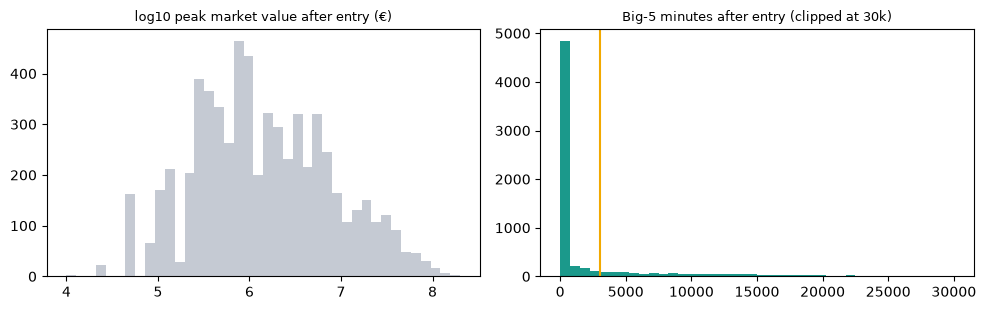

real_outcomes.parquet: (6619, 30)


In [15]:
# Made-it sensitivity by band (matched players only). Notebook 05 decides how to treat unmatched players.
r2 = real.merge(coh[["player_id", "potential_band"]].rename(columns={"player_id": "fifa_player_id"}), on="fifa_player_id")
sens = r2.groupby("potential_band", observed=True).agg(
    matched=("fifa_player_id", "size"),
    **{f"made_it_{t}_%": (f"made_it_{t}", lambda s: round(s.mean() * 100, 1)) for t in config.MADE_IT_MINUTES_SENSITIVITY})
sens.index = sens.index.astype(str)
display(sens)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(np.log10(real["peak_market_value_eur"].dropna() + 1), bins=40, color=config.PALETTE["context"])
ax[0].set_title("log10 peak market value after entry (€)", fontsize=9)
ax[1].hist(real["big5_minutes"].clip(upper=30000), bins=40, color=config.PALETTE["reality"])
ax[1].axvline(config.MADE_IT_MINUTES_DEFAULT, color=config.PALETTE["promise"])
ax[1].set_title("Big-5 minutes after entry (clipped at 30k)", fontsize=9)
plt.tight_layout(); plt.show()

real.to_parquet(config.CLEAN / "real_outcomes.parquet", index=False)
print("real_outcomes.parquet:", real.shape)

## 10. Write to `reports/data_quality.md`

In [16]:
checks = pd.DataFrame(CHECKS)
cov_md = cov.reset_index()[["competition_id", "name", "type", "first", "last", "appearances"]].sort_values("first", ascending=False)
cov_md["first"] = cov_md["first"].dt.strftime("%Y-%m-%d"); cov_md["last"] = cov_md["last"].dt.strftime("%Y-%m-%d")
body = f'''
### Match results

{dq.df_to_md(best["match_method"].value_counts().rename_axis("Method").reset_index(name="Players"))}

Raw match class (before overrides): {", ".join(f"{k} {v:,}" for k, v in best["match_class"].value_counts().items())}.

### Match rate by potential band (accepted matches; pending review counts as unmatched)

{dq.df_to_md(rate.reset_index().rename(columns={"potential_band": "Band", "index": "Band"}))}

### Review queue

`reports/match_review.csv`: {review["fifa_player_id"].nunique():,} players, {len(review):,} candidate rows.

{dq.df_to_md(review_summary.rename_axis("Reason").reset_index(name="Players"))}

### Appearance coverage

{len(late)} competition(s) have records starting after the first entry date ({first_entry:%Y-%m-%d}).
Big-5 seasons with fewer than half the median appearance count: {thin_cells if thin_cells else "none"}.

{dq.df_to_md(cov_md)}

### Real outcomes

- Matched players: {len(real):,}. With no valuation after entry: {n_no_val:,}.
- Latest transfer is taken on or before the data snapshot date ({snapshot_date:%Y-%m-%d}); {n_future} later-dated transfers are ignored.

{dq.df_to_md(sens.reset_index().rename(columns={"potential_band": "Band"}))}

### Notes

{chr(10).join("- " + n for n in NOTES)}

### Checks

{dq.df_to_md(checks)}
'''
dq.write_section("02", "02 Transfermarkt match", body)
print("Written to", config.DATA_QUALITY.relative_to(ROOT))

Written to reports/data_quality.md


## 11. Summary

In [17]:
display(checks)
assert (checks["Result"] == "PASS").all(), checks[checks["Result"] == "FAIL"]

,Check,Result,Detail
0,TM player_id is unique,PASS,
1,Override file is valid,PASS,
2,No TM player is accepted for two FIFA players,PASS,
3,Match rate >= 90% in band 80–84,PASS,92.2%
4,Match rate >= 90% in band 85+,PASS,100.0%
5,Crosswalk has one row per cohort entrant,PASS,
6,TM appearance_id is unique,PASS,
7,Follow-up window ends inside the data for ever...,PASS,
8,made_it_5y implies made_it,PASS,
9,Big-5 minutes are included in all-covered top-...,PASS,
